<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/16_ICS_SCADA_Cyber_Physical_Attacks/QSVM_AnomalyDetection_Cultice2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum-kernel One-Class SVM for cyber-physical anomaly detection: Cultice et al. (2024) step by step

This notebook re-implements, runs and checks the method of

> Tyler Cultice, Md. Saif Hassan Onim, Annarita Giani and Himanshu Thapliyal,
> "Anomaly Detection for Real-World Cyber-Physical Security using Quantum Hybrid Support Vector Machines",
> IEEE Computer Society Annual Symposium on VLSI (ISVLSI) 2024, DOI 10.1109/ISVLSI61997.2024.00117, arXiv:2409.04935.

The authors publish no code, so everything below is written from the method as the paper describes it, with the same
software stack (Qiskit for the quantum kernel, scikit-learn for the SVM).

**What the notebook does.** It downloads the public HAI 20.07 industrial-control-system dataset (a steam-turbine and
hydro-power testbed with 59 sensors and 38 attacks), smooths it with a 60-second moving average, ranks the sensors
with a decision tree (Gini importance), encodes 16 chosen sensors into 8 qubits (two features per qubit), computes a
quantum fidelity kernel `K(x, y) = |<phi(x)|phi(y)>|^2` between every pair of samples, exponentiates it, and feeds it to a
One-Class SVM that is trained on normal operation only. It then tests on 1000 normal and 500 anomalous samples (the
paper's Fig. 5 composition) and reports accuracy and the weighted precision / recall / F1 of the paper's Table I. The
paper's own classical comparator (a One-Class SVM with an RBF kernel on the same features) and supervised reference models
are trained on exactly the same inputs. The last sections draw the paper's Fig. 5 kernel picture again and put every number
the paper reports next to ours with a verdict.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. With `FAST_MODE = True`
(4 and 8 qubits only, small samples) it finishes in a few minutes on a CPU; with
`FAST_MODE = False` it uses the paper's test sizes, 12 qubits and more repetitions (runtime stated in the configuration cell).
The data (about 110 MB, four compressed CSV files) is downloaded from the dataset authors' GitHub repository on the first run.

**What you get at the end.** Tables and figures that mirror the paper's Table I and Fig. 5, confusion matrices, a
threshold-free AUC for every model, ablations that show which design choice matters (feature ranking, angle scaling,
natural 4 % anomaly rate), and an honest verdict on each claim of the paper.

## The paper in one page

**Problem.** Cyber-physical systems (power plants, water plants) are run by feedback loops that read hundreds of sensors.
An attacker who tampers with sensor or actuator values should be noticed from the sensor streams alone. This is
*anomaly detection*: decide for each time step whether the 59 sensor readings are normal or attacked.

**Decision.** Binary: normal (0) / anomalous (1). The model is a **One-Class SVM** (OCSVM): trained only on normal operation,
it learns the region of feature space that normal data occupies and flags anything outside it.

**Method.**
1. Moving average over 60 overlapping one-second samples (Eq. 2) to reduce noise; categorical columns replaced by
   histogram (frequency) values; z-score standardisation (Eq. 3).
2. Feature selection: rank the sensors by Gini importance of a decision tree and keep the top `N`, where `N` = 2 x number of
   qubits (two features per qubit, "dense angle encoding").
3. Feature map (Fig. 4): per qubit a generic rotation (`U` gate) that loads two features, nearest-neighbour entanglement,
   a further rotation, the whole block repeated **3 times**; data scaled to [-pi, pi].
4. Fidelity kernel via the Hilbert-Schmidt / "compute-uncompute" overlap (Fig. 1), `K(x, y) = |<phi(x)|phi(y)>|^2`
   (Eq. 1), noiseless Qiskit simulation; post-processed as `k' = exp(k)`.
5. `sklearn.svm.OneClassSVM` with the precomputed kernel; test samples with low similarity to the training set are anomalies.

**Data.** HAI 20.07 (Shin et al., USENIX CSET 2020): 59 sensor/actuator features, 1 Hz; train 177 h normal, test 123 h with
38 attacks; about 4 % of the test rows are anomalous. The paper evaluates on a mixture of 1000 normal and 500 anomalous test
samples (Fig. 5) to handle the imbalance.

**Claims.**

| Features (qubits) | Quantum acc | prec | rec | F1 | Classical acc | prec | rec | F1 |
|---|---|---|---|---|---|---|---|---|
| 8 (4) | 86 % | 0.87 | 0.86 | 0.85 | 74 % | 0.81 | 0.74 | 0.67 |
| 16 (8) | **87 %** | 0.88 | 0.87 | **0.86** | 73 % | 0.81 | 0.73 | 0.65 |
| 24 (12) | 82 % | 0.82 | 0.82 | 0.82 | 72 % | 0.79 | 0.72 | 0.65 |

Further claims: the quantum kernel is 14 accuracy points and 0.21 F1 better than the classical counterpart on the same
features; 16 features / 8 qubits is the best setting; anomalous test samples have visibly lower fidelity to the training
data (Fig. 5); the classical kernel has high precision but poor recall while the quantum kernel is good at both.
Table II of the paper only quotes other authors' results on other datasets and cannot be re-run here.
(Note that recall equals accuracy in every row of Table I: the paper's precision / recall / F1 are **weighted averages**
over the two classes, which this notebook reproduces.)

## What follows the paper and what had to be chosen

The paper is a short conference paper and leaves many details open. Every choice made here is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | HAI 20.07 | HAI 20.07 (train1, train2, test1, test2 from the authors' GitHub repository) |
| Moving average | 60 overlapping samples | same; computed per file; a window is labelled by the label of its last second; normal windows that contain attack seconds are dropped |
| Categorical columns | "replaced by histogram values" | columns with at most 10 distinct values replaced by their relative frequency in the normal training data, before averaging |
| Standardisation | z-score | z-score fitted on normal training windows |
| Feature ranking | Gini importance of a decision tree; labelled data and split not stated | tree fitted on a **labelled calibration block** = first 40 % of the test1 timeline, kept apart from every evaluation row (ablation: tree fitted on train2 only, and the paper-literal variant that sees all labelled data) |
| Feature count | 8, 16, 24 (4, 8, 12 qubits) | same |
| Feature map | Fig. 4: `U` gates (two angles), nearest-neighbour entanglement, further rotation, 3 repetitions | `U(x_2q, x_2q+1, 0)` -> chain of CNOTs -> `RY(x_2q)`, `RZ(x_2q+1)`, repeated 3 times (Fig. 4 is a drawing without gate parameters, so the gate choice is ours) |
| Data scaling | normalised to [-pi, pi] | z-score times a **bandwidth** `bw`, clipped to [-pi, pi]; `bw` tuned on the validation block (ablation shows plain min-max scaling) |
| Kernel | fidelity, `exp(k)` post-processing | same, `FidelityStatevectorKernel` semantics; sweeps use a vectorised statevector simulator that is checked against Qiskit |
| OCSVM `nu` | not stated | tuned on the validation block from a small grid |
| Classical comparator | "classical counterpart with the same features" | OCSVM with RBF kernel, `gamma` and `nu` tuned on the same validation block with the same budget |
| Training set size | not stated | `N_TRAIN` normal windows drawn at random from train1 + train2 |
| Test set | 1000 normal + 500 anomalous | same composition, random draws from the evaluation pool, repeated over seeds |
| Metrics | accuracy, weighted precision / recall / F1 | same, plus attack-class precision / recall / F1 and ROC-AUC |
| Noise | none (ideal simulation) | none |
| Seeds, repetitions | not stated | `SEED = 42`, several repetitions (mean +- std) |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE  = False      # True: class demo, 4 and 8 qubits, about 4 min on CPU. False: the paper's test sizes (1000+500), 5 seeds, 4/8/12 qubits; about 28 min on a 4-core CPU (12 qubits dominate)
SEED       = 42             # CHOICE: the paper gives no seed
IBM_TOKEN  = ""             # unused: the paper simulates without noise, so no hardware or noisy backend is needed

DATA_DIR   = "hai_data"     # cache folder for the downloaded HAI files (relative to the working directory)
HAI_LOCAL_DIR = ""          # optional: folder that already holds train1/train2/test1/test2 .csv.gz files

WINDOW        = 60          # paper: moving average over 60 overlapping samples
CAT_MAX_UNIQUE = 10         # CHOICE: columns with at most this many distinct values count as categorical
CAL_FRACTION  = 0.40        # CHOICE: first 40 % of test1 = labelled calibration block (feature ranking + tuning)
REPS          = 3           # paper: the feature-map block is repeated 3 times
FEATURE_COUNTS = (8, 16) if FAST_MODE else (8, 16, 24)   # paper Table I: 4, 8, 12 qubits (12 qubits only in the full run: 4096-dim statevectors)
N_FEATURES_MAIN = 16        # the paper's best / headline setting: 16 features = 8 qubits

if FAST_MODE:
    N_TRAIN = 400                      # CHOICE: normal windows the OCSVM is trained on
    N_TEST_NORMAL, N_TEST_ANOM = 500, 250   # same 2:1 mix as the paper, half size
    N_VAL_NORMAL,  N_VAL_ANOM  = 500, 250   # validation block drawn from the calibration block
    N_SUP_NORMAL,  N_SUP_ANOM  = 400, 200   # labelled draw for the supervised reference models
    N_SEEDS   = 2
    BW_GRID   = (0.05, 0.1, 0.2, 0.4)  # CHOICE: angle bandwidth candidates
    NU_GRID   = (0.001, 0.01, 0.05)
    GAMMA_MULTS = (0.25, 0.5, 1.0, 2.0)      # multiples of sklearn's gamma="scale" for the classical OCSVM
    N_REALISTIC = 5000                 # rows for the natural-prevalence (4 % anomalies) test
else:
    N_TRAIN = 1000
    N_TEST_NORMAL, N_TEST_ANOM = 1000, 500  # paper Fig. 5
    N_VAL_NORMAL,  N_VAL_ANOM  = 1000, 500
    N_SUP_NORMAL,  N_SUP_ANOM  = 1000, 500
    N_SEEDS   = 5
    BW_GRID   = (0.025, 0.05, 0.1, 0.2, 0.4, 0.8)
    NU_GRID   = (0.001, 0.003, 0.01, 0.03, 0.1)
    GAMMA_MULTS = (0.1, 0.25, 0.5, 1.0, 2.0, 4.0)
    N_REALISTIC = 20000
N_QISKIT_CHECK = 40         # samples used to compare the fast simulator with Qiskit's statevector kernel

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn, scipy
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import OneClassSVM, SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.utils import algorithm_globals

algorithm_globals.random_seed = SEED          # Qiskit-ML global seed (no stochastic step here, kept for completeness)
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1
numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1


## 1. The HAI 20.07 dataset

HAI ("HIL-based Augmented ICS", Shin et al., 2020) comes from a physical testbed that emulates a steam-turbine and a
hydro-power plant with real PLCs: a boiler (process P1), a turbine (P2), a water-treatment tank system (P3) and a
hardware-in-the-loop simulation of the power grid (P4). Version 20.07 holds four files sampled once per second, with 59
sensor / actuator columns (`P1_B2004`, `P1_FT01`, ...) and the labels `attack`, `attack_P1`, `attack_P2`, `attack_P3`:

* `train1`, `train2`: operation without attacks (the paper: "177 hours"); in the public release `train2` still contains two
  short attack episodes, which we keep out of the normal pool;
* `test1`, `test2`: normal and attacked operation (the paper: "123 hours", 38 attacks, about 4 % anomalous rows).

The cell downloads the files from the authors' GitHub repository `icsdataset/hai` (three mirror URLs are tried in turn) and
caches them in `DATA_DIR`. You can also set `HAI_LOCAL_DIR` to a folder that already contains the four `.csv.gz` files.

In [4]:
HAI_FILES = ["train1", "train2", "test1", "test2"]
HAI_URLS = [  # CHOICE: three public mirrors of the same files, tried in this order
    "https://raw.githubusercontent.com/icsdataset/hai/master/hai-20.07/{f}.csv.gz",
    "https://media.githubusercontent.com/media/icsdataset/hai/master/hai-20.07/{f}.csv.gz",
    "https://cdn.jsdelivr.net/gh/icsdataset/hai@master/hai-20.07/{f}.csv.gz",
]

def _valid_gz_csv(path):
    try:
        d = pd.read_csv(path, sep=";", nrows=3)
        return "attack" in d.columns and d.shape[1] >= 60
    except Exception:
        return False

def fetch_hai(name):
    local = os.path.join(HAI_LOCAL_DIR, f"{name}.csv.gz") if HAI_LOCAL_DIR else None
    if local and os.path.exists(local) and _valid_gz_csv(local):
        return local
    dest = os.path.join(DATA_DIR, f"hai20.07_{name}.csv.gz")
    if os.path.exists(dest) and _valid_gz_csv(dest):
        return dest
    for tmpl in HAI_URLS:
        url = tmpl.format(f=name)
        try:
            with requests.get(url, stream=True, timeout=120) as r:
                r.raise_for_status()
                with open(dest, "wb") as fh:
                    for chunk in r.iter_content(1 << 20):
                        fh.write(chunk)
            if _valid_gz_csv(dest):
                print(f"{name}: downloaded from {url} ({os.path.getsize(dest)/1e6:.1f} MB)")
                return dest
            print(f"{name}: file from {url} was not a valid HAI CSV (Git-LFS pointer?), trying next mirror")
        except Exception as exc:
            print(f"{name}: {url} failed ({type(exc).__name__}: {exc}), trying next mirror")
    raise RuntimeError(f"Could not obtain HAI file {name}. Download hai-20.07 from https://github.com/icsdataset/hai "
                       f"and set HAI_LOCAL_DIR to the folder that holds the .csv.gz files.")

t0 = time.time()
paths = {f: fetch_hai(f) for f in HAI_FILES}
raw = {f: pd.read_csv(p, sep=";") for f, p in paths.items()}
print(f"loaded in {time.time()-t0:.0f} s")
for f, d in raw.items():
    print(f"{f}: {d.shape[0]:>7} rows x {d.shape[1]} columns | {d['time'].iloc[0]} -> {d['time'].iloc[-1]} | "
          f"attack rows {int(d['attack'].sum()):>6} ({100*d['attack'].mean():.2f} %)")
SENSORS = [c for c in raw["train1"].columns if c not in ("time", "attack", "attack_P1", "attack_P2", "attack_P3")]
print(len(SENSORS), "sensor / actuator columns (paper: 59)")

loaded in 31 s
train1:  309600 rows x 64 columns | 2019-09-11 20:00:00 -> 2019-09-15 09:59:59 | attack rows      0 (0.00 %)
train2:  241200 rows x 64 columns | 2019-11-01 20:00:00 -> 2019-11-04 14:59:59 | attack rows    776 (0.32 %)
test1:  291600 rows x 64 columns | 2019-10-29 11:00:00 -> 2019-11-01 19:59:59 | attack rows  11538 (3.96 %)
test2:  153000 rows x 64 columns | 2019-11-04 15:00:00 -> 2019-11-06 09:29:59 | attack rows   5989 (3.91 %)
59 sensor / actuator columns (paper: 59)


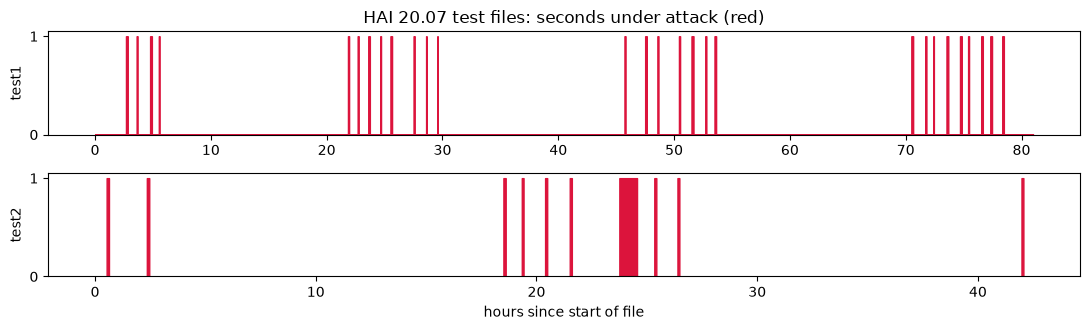

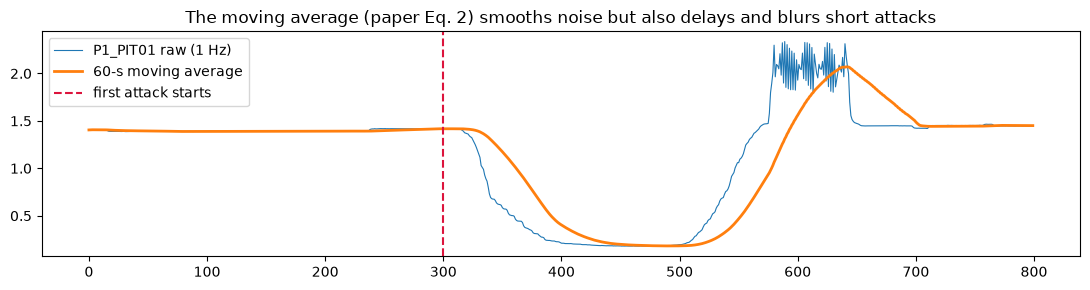

In [5]:
# Where are the attacks? Label timeline of the two test files, and one sensor before / after the moving average.
fig, ax = plt.subplots(2, 1, figsize=(11, 3.4), sharex=False)
for a, f in zip(ax, ["test1", "test2"]):
    a.fill_between(np.arange(len(raw[f])) / 3600, raw[f]["attack"].values, step="mid", color="crimson")
    a.set_ylabel(f); a.set_yticks([0, 1]); a.set_ylim(0, 1.05)
ax[1].set_xlabel("hours since start of file"); ax[0].set_title("HAI 20.07 test files: seconds under attack (red)")
plt.tight_layout(); plt.show()

d = raw["test1"]; a0 = int(np.flatnonzero(np.diff(d["attack"].values) == 1)[0])
seg = d.iloc[a0 - 300: a0 + 500]
col = "P1_PIT01"
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(seg[col].values, lw=0.8, label=f"{col} raw (1 Hz)")
ax.plot(seg[col].rolling(WINDOW, min_periods=1).mean().values, lw=2, label=f"{WINDOW}-s moving average")
ax.axvline(300, color="crimson", ls="--", label="first attack starts")
ax.legend(); ax.set_title("The moving average (paper Eq. 2) smooths noise but also delays and blurs short attacks")
plt.tight_layout(); plt.show()

## 2. Pre-processing: moving average, histogram values, z-score

Following Section IV-A of the paper:

1. **Moving average** over 60 overlapping one-second samples, `m_t = (1/w) * sum_{i=t-w+1..t} x_i`, computed separately for
   every file (so no window crosses a file boundary).
2. **Categorical columns**: ten columns of HAI have at most ten distinct values (switches, set-point states). The paper
   replaces categorical values "with their numerical histogram values"; we replace every raw value by its relative
   frequency in the normal training data. # CHOICE: done before averaging, because an average of category codes is meaningless.
3. **Standardisation** `(x - mean)/std` with mean and standard deviation of the **normal training windows only**.

A *window* is labelled by the label of the last second (what a real-time detector would decide at that moment). Normal
windows that still contain attack seconds (the minute after an attack ends) are dropped because their label would be
ambiguous. # CHOICE: this keeps the "normal" class clean.

In [6]:
CAT_COLS = [c for c in SENSORS if raw["train1"][c].nunique() <= CAT_MAX_UNIQUE]           # CHOICE
FREQ = {c: raw["train1"][c].value_counts(normalize=True).to_dict() for c in CAT_COLS}      # histogram values from train1
print("categorical columns (replaced by histogram values):", CAT_COLS)

def make_windows(df):
    d = df[SENSORS].copy()
    for c in CAT_COLS:
        d[c] = d[c].map(FREQ[c]).fillna(0.0)
    X = d.rolling(WINDOW).mean().iloc[WINDOW - 1:].to_numpy(dtype=np.float32)
    att = df["attack"].to_numpy()
    y = att[WINDOW - 1:]
    any_att = pd.Series(att).rolling(WINDOW).max().to_numpy()[WINDOW - 1:]
    keep = ~((any_att == 1) & (y == 0))             # CHOICE: drop normal-labelled windows that touch an attack
    return X[keep], y[keep].astype(int)

W = {f: make_windows(raw[f]) for f in HAI_FILES}
X_tr1, y_tr1 = W["train1"]; X_tr2, y_tr2 = W["train2"]; X_te1, y_te1 = W["test1"]; X_te2, y_te2 = W["test2"]

# Normal training pool: all windows of train1 and the attack-free windows of train2
X_pool = np.vstack([X_tr1, X_tr2[y_tr2 == 0]])
MU = X_pool.mean(axis=0, dtype=np.float64)
SD = X_pool.std(axis=0, dtype=np.float64); SD[SD == 0] = 1.0     # constant columns stay at 0 after scaling
def Z(X):  # z-score using the normal training windows only
    return (np.asarray(X, dtype=np.float64) - MU) / SD

# Labelled calibration block = first CAL_FRACTION of the test1 timeline; the evaluation pool is everything after it plus test2.
n_cal = int(CAL_FRACTION * len(X_te1))
X_cal, y_cal = X_te1[:n_cal], y_te1[:n_cal]
X_ev = np.vstack([X_te1[n_cal:], X_te2]); y_ev = np.concatenate([y_te1[n_cal:], y_te2])
print(f"normal training pool : {len(X_pool):>7} windows")
print(f"calibration block    : {len(X_cal):>7} windows, {int(y_cal.sum())} anomalous ({100*y_cal.mean():.2f} %)")
print(f"evaluation pool      : {len(X_ev):>7} windows, {int(y_ev.sum())} anomalous ({100*y_ev.mean():.2f} %)  (paper: about 4 %)")
print(f"train2 labelled      : {len(X_tr2):>7} windows, {int(y_tr2.sum())} anomalous")

categorical columns (replaced by histogram values): ['P1_PCV02D', 'P2_Auto', 'P2_Emgy', 'P2_On', 'P2_SD01', 'P2_TripEx', 'P3_LH', 'P3_LL', 'P4_HT_PS', 'P4_ST_PS']


normal training pool :  549788 windows
calibration block    :  115955 windows, 4352 anomalous (3.75 %)
evaluation pool      :  326285 windows, 13175 anomalous (4.04 %)  (paper: about 4 %)
train2 labelled      :  241023 windows, 776 anomalous


## 3. Feature selection by decision-tree (Gini) importance

The paper ranks the sensors "from a decision tree by the Gini impurity" and keeps as many as the qubits can encode
(`2 x qubits`). A decision tree needs labels, and the paper does not say which labelled data it used. If the tree is fitted on
the data that is later used for testing, the selection leaks information about the test attacks. To avoid that, the tree here is
fitted on the **calibration block** (the first 40 % of test1 in time), and **no calibration row is ever used for testing**.
The same block provides the validation data for the hyper-parameters in Section 6. (Section 9 shows what happens with the
other possible readings: a tree fitted only on `train2`, and the paper-literal tree that sees everything.)

sensors with non-zero importance: 49 of 59


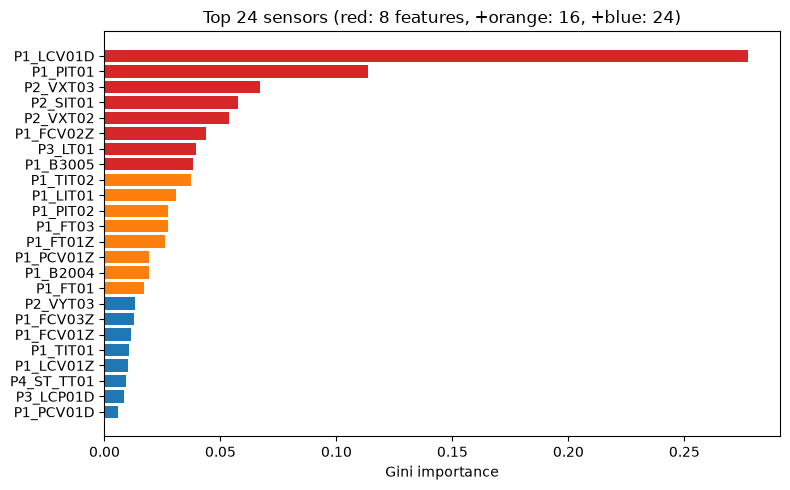

In [7]:
def gini_rank(X, y):
    """Sensors sorted by decreasing Gini importance of one decision tree (fitted on standardised windows)."""
    dt = DecisionTreeClassifier(random_state=SEED, class_weight="balanced").fit(Z(X), y)   # CHOICE: balanced classes, full depth
    imp = dt.feature_importances_
    return np.argsort(-imp, kind="stable"), imp

RANK_CAL, IMP_CAL = gini_rank(X_cal, y_cal)
top = pd.DataFrame({"sensor": [SENSORS[i] for i in RANK_CAL[:24]], "gini importance": IMP_CAL[RANK_CAL[:24]].round(3)})
print("sensors with non-zero importance:", int((IMP_CAL > 0).sum()), "of", len(SENSORS))

fig, ax = plt.subplots(figsize=(8, 5))
colors = ["tab:red" if r < 8 else "tab:orange" if r < 16 else "tab:blue" for r in range(24)]
ax.barh(range(24)[::-1], IMP_CAL[RANK_CAL[:24]], color=colors)
ax.set_yticks(range(24)[::-1]); ax.set_yticklabels([SENSORS[i] for i in RANK_CAL[:24]])
ax.set_xlabel("Gini importance"); ax.set_title("Top 24 sensors (red: 8 features, +orange: 16, +blue: 24)")
plt.tight_layout(); plt.show()

## 4. The quantum feature map (paper Fig. 4)

Each qubit carries **two** features ("dense angle encoding"), so 16 features need 8 qubits. The circuit of Fig. 4 is drawn
without gate parameters in the paper; it says: generic rotation (`U`) gates that load the data, nearest-neighbour entanglement,
a further rotation, and the whole block "repeated three times". We implement exactly that:

```
for rep in range(3):
    for each qubit q:   U(theta = x[2q], phi = x[2q+1], lambda = 0)     # loads two features
    for q in 0..n-2:    CNOT(q, q+1)                                     # nearest-neighbour entanglement
    for each qubit q:   RY(x[2q]); RZ(x[2q+1])                           # "repeated rotation"
```

`# CHOICE:` the third `U` angle is fixed to 0, and the rotation after the entangler re-uses the same two features; Fig. 4 does
not fix either detail.

**Kernel.** For two samples `x` and `y` the overlap `|<phi(x)|phi(y)>|^2` equals the probability of measuring the all-zero
string after `U(x)` followed by `U(y)^dagger` (the Hilbert-Schmidt / compute-uncompute test of Fig. 1). With no noise and no
shot noise this probability is exactly the squared overlap of the two statevectors, which is what Qiskit's
`FidelityStatevectorKernel` computes.

**Speed trick.** Qiskit builds one `Statevector` per sample in Python (about 10 to 30 ms for 8 qubits), which is slow for the
sweeps below. We therefore also write a small vectorised numpy simulator of the very same circuit and **check it against
Qiskit** (Section 5). The fast simulator is used for tuning and sweeps, Qiskit's kernel for the headline configuration.

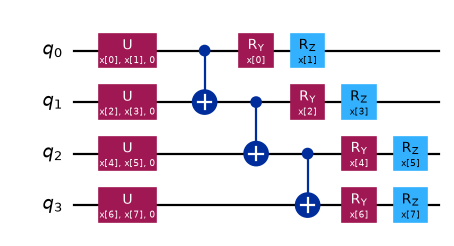

In [8]:
def paper_feature_map(n_features, reps=REPS):
    """Fig. 4 feature map as a parameterised Qiskit circuit (n_features = 2 x n_qubits)."""
    nq = n_features // 2
    x = ParameterVector("x", n_features)
    qc = QuantumCircuit(nq, name=f"FeatureMap{n_features}")
    for _ in range(reps):
        for q in range(nq):
            qc.u(x[2 * q], x[2 * q + 1], 0.0, q)         # CHOICE: lambda = 0
        for q in range(nq - 1):
            qc.cx(q, q + 1)                              # nearest-neighbour entanglement
        for q in range(nq):
            qc.ry(x[2 * q], q); qc.rz(x[2 * q + 1], q)   # CHOICE: repeated rotation re-uses the same features
    return qc

paper_feature_map(8, reps=1).draw("mpl", fold=-1, scale=0.8)

In [9]:
# ---- vectorised statevector simulator of the circuit above (all samples at once) ----
def _u(th, ph, lam):
    c, s = np.cos(th / 2), np.sin(th / 2)
    M = np.empty(th.shape + (2, 2), dtype=complex)
    M[..., 0, 0] = c;                 M[..., 0, 1] = -np.exp(1j * lam) * s
    M[..., 1, 0] = np.exp(1j * ph) * s; M[..., 1, 1] = np.exp(1j * (ph + lam)) * c
    return M
def _ry(th):
    c, s = np.cos(th / 2), np.sin(th / 2)
    M = np.empty(th.shape + (2, 2), dtype=complex)
    M[..., 0, 0] = c; M[..., 0, 1] = -s; M[..., 1, 0] = s; M[..., 1, 1] = c
    return M
def _rz(th):
    M = np.zeros(th.shape + (2, 2), dtype=complex)
    M[..., 0, 0] = np.exp(-1j * th / 2); M[..., 1, 1] = np.exp(1j * th / 2)
    return M
def _apply1(psi, M, q, n):                      # Qiskit little-endian: qubit q is tensor axis n-1-q
    B = psi.shape[0]
    t = np.moveaxis(psi.reshape((B,) + (2,) * n), 1 + (n - 1 - q), 1)
    sh = t.shape
    t = np.einsum("bij,bjr->bir", M, t.reshape(B, 2, -1)).reshape(sh)
    return np.moveaxis(t, 1, 1 + (n - 1 - q)).reshape(B, -1)
def _cx(psi, c, t, n):
    idx = np.arange(2 ** n); perm = idx.copy()
    perm[((idx >> c) & 1).astype(bool)] ^= (1 << t)
    return psi[:, perm]

def statevectors(X, reps=REPS):
    X = np.asarray(X, float); B, nf = X.shape; n = nf // 2
    psi = np.zeros((B, 2 ** n), dtype=complex); psi[:, 0] = 1
    for _ in range(reps):
        for q in range(n):
            psi = _apply1(psi, _u(X[:, 2 * q], X[:, 2 * q + 1], np.zeros(B)), q, n)
        for q in range(n - 1):
            psi = _cx(psi, q, q + 1, n)
        for q in range(n):
            psi = _apply1(psi, _ry(X[:, 2 * q]), q, n)
            psi = _apply1(psi, _rz(X[:, 2 * q + 1]), q, n)
    return psi

def fast_kernel(A, B=None):
    """K[i, j] = |<phi(A_i)|phi(B_j)>|^2 (B defaults to A)."""
    sa = statevectors(A)
    sb = sa if B is None else statevectors(B)
    return np.abs(sa.conj() @ sb.T) ** 2

## 5. Check: the fast simulator equals Qiskit's fidelity kernel

Before trusting the fast simulator we compare it with `FidelityStatevectorKernel` of qiskit-machine-learning (an exact
statevector fidelity, no sampling noise) and with a hand-made `Statevector` overlap, on random angle vectors for 8, 16 and 24
features. `enforce_psd=False` keeps Qiskit from projecting the matrix, so the two should agree to rounding error.

In [10]:
chk = np.random.default_rng(SEED)
rows = []
for nf in (8, 16, 24):
    A = chk.uniform(-np.pi, np.pi, (N_QISKIT_CHECK if nf < 24 else 12, nf))
    B = chk.uniform(-np.pi, np.pi, (6, nf))
    fm = paper_feature_map(nf)
    qk = FidelityStatevectorKernel(feature_map=fm, enforce_psd=False)
    t = time.time(); Kq = qk.evaluate(B, A); tq = time.time() - t
    t = time.time(); Kf = fast_kernel(B, A); tf = time.time() - t
    # by hand with Qiskit Statevector objects
    sv = lambda v: Statevector(fm.assign_parameters(v))
    Kh = np.array([[abs(sv(b).inner(sv(a))) ** 2 for a in A[:5]] for b in B[:3]])
    rows.append(dict(features=nf, qubits=nf // 2, max_abs_diff_fast_vs_qiskit=np.abs(Kq - Kf).max(),
                     max_abs_diff_by_hand=np.abs(Kh - Kf[:3, :5]).max(),
                     allclose=bool(np.allclose(Kq, Kf, atol=1e-10) and np.allclose(Kh, Kf[:3, :5], atol=1e-10)),
                     qiskit_s=round(tq, 2), fast_s=round(tf, 3)))
display(pd.DataFrame(rows))
assert all(r["allclose"] for r in rows), "fast simulator disagrees with Qiskit"

,features,qubits,max_abs_diff_fast_vs_qiskit,max_abs_diff_by_hand,allclose,qiskit_s,fast_s
0,8,4,2.498002e-16,1.110223e-16,True,0.24,0.012
1,16,8,2.775558e-17,9.540979e-18,True,0.63,0.137
2,24,12,2.602085e-18,2.602085e-18,True,0.46,0.269


## 6. Models, metrics and hyper-parameter tuning

**Quantum model (paper).** angles `= clip(z * bw, -pi, pi)` for the selected sensors, fidelity kernel `K`, post-processing
`exp(K)`, `OneClassSVM(kernel="precomputed", nu)` trained on normal windows only; a test sample is flagged anomalous when the
OCSVM predicts `-1`.

**Classical counterpart.** `OneClassSVM(kernel="rbf")` on the identical angle features.

**Supervised references (not in the paper).** Because the paper's Table I contrasts a one-class quantum model with a
"typical classical SVM", we also train, on a small *labelled* draw from the calibration block, a `RandomForestClassifier`,
an RBF `SVC`, and an `SVC` with the same quantum kernel. These show what the features can deliver when anomaly examples
are available.

**Hyper-parameters (not given in the paper).** The angle bandwidth `bw` and `nu` for the quantum model, and `gamma`
(multiples of sklearn's `scale`) and `nu` for the classical model, are chosen **on a validation draw from the calibration
block** by weighted F1, with equal grid sizes for both models. Nothing is tuned on the evaluation rows.

**Metrics** are the paper's: accuracy and the *weighted* precision, recall and F1 over the two classes (so weighted recall
equals accuracy, as in the paper's Table I), plus attack-class precision / recall / F1 and the ROC-AUC of the anomaly score.

In [11]:
def metrics(y, p, score=None):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
    apr, arc, af1, _ = precision_recall_fscore_support(y, p, average="binary", pos_label=1, zero_division=0)
    out = dict(acc=accuracy_score(y, p), prec=pr, rec=rc, f1=f1, att_prec=apr, att_rec=arc, att_f1=af1,
               cm=confusion_matrix(y, p, labels=[0, 1]))
    out["auc"] = roc_auc_score(y, score) if score is not None and len(np.unique(y)) == 2 else np.nan
    return out

def angles(Zs, sel, bw):                      # standardised data -> rotation angles in [-pi, pi]
    return np.clip(Zs[:, sel] * bw, -np.pi, np.pi)

# ---- sampling helpers (all draws are seeded) ----
cal_norm = np.flatnonzero(y_cal == 0); cal_att = np.flatnonzero(y_cal == 1)
ev_norm  = np.flatnonzero(y_ev == 0);  ev_att  = np.flatnonzero(y_ev == 1)
_r = np.random.default_rng(SEED + 1000)
_pn, _pa = _r.permutation(cal_norm), _r.permutation(cal_att)
VAL_IDX = np.r_[_pn[:N_VAL_NORMAL], _pa[:N_VAL_ANOM]]                       # validation draw (calibration block)
SUP_IDX = np.r_[_pn[N_VAL_NORMAL:N_VAL_NORMAL + N_SUP_NORMAL], _pa[N_VAL_ANOM:N_VAL_ANOM + N_SUP_ANOM]]   # disjoint labelled draw
y_val = y_cal[VAL_IDX]; y_sup = y_cal[SUP_IDX]

def draw_train(seed):                          # normal windows for the OCSVM
    return np.random.default_rng(SEED + seed).choice(len(X_pool), N_TRAIN, replace=False)
def draw_test(seed, n_norm=N_TEST_NORMAL, n_anom=N_TEST_ANOM):   # paper: 1000 normal then 500 anomalous
    r = np.random.default_rng(SEED + 500 + seed)
    idx = np.r_[r.choice(ev_norm, n_norm, replace=False), r.choice(ev_att, n_anom, replace=False)]
    return idx, np.r_[np.zeros(n_norm, int), np.ones(n_anom, int)]

def ocsvm_scores_q(Ktr_raw, Kte_raw, nu):      # paper: k' = exp(k), precomputed OCSVM
    oc = OneClassSVM(kernel="precomputed", nu=nu).fit(np.exp(Ktr_raw))
    D = oc.decision_function(np.exp(Kte_raw))
    return (D < 0).astype(int), -D             # prediction (1 = anomaly) and anomaly score
def ocsvm_scores_c(Atr, Ate, nu, gmult):
    gamma = gmult / (Atr.shape[1] * Atr.var())     # = gmult x sklearn's gamma="scale"
    oc = OneClassSVM(kernel="rbf", gamma=gamma, nu=nu).fit(Atr)
    D = oc.decision_function(Ate)
    return (D < 0).astype(int), -D

def tune(sel):
    """Pick (bw, nu) for the quantum OCSVM and (gamma multiple, nu) for the classical OCSVM on the validation draw."""
    Ztr = Z(X_pool[draw_train(0)]); Zv = Z(X_cal[VAL_IDX])
    best_q = (-1, None); best_c = (-1, None); log = []
    for bw in BW_GRID:
        A, Av = angles(Ztr, sel, bw), angles(Zv, sel, bw)
        Ktr, Kv = fast_kernel(A), fast_kernel(Av, A)
        for nu in NU_GRID:
            p, s = ocsvm_scores_q(Ktr, Kv, nu); f1 = metrics(y_val, p)["f1"]; log.append(("quantum", bw, nu, f1))
            if f1 > best_q[0]: best_q = (f1, dict(bw=bw, nu=nu))
    A0, Av0 = angles(Ztr, sel, 1.0), angles(Zv, sel, 1.0)
    for gm in GAMMA_MULTS:
        for nu in NU_GRID:
            p, s = ocsvm_scores_c(A0, Av0, nu, gm); f1 = metrics(y_val, p)["f1"]; log.append(("classical", gm, nu, f1))
            if f1 > best_c[0]: best_c = (f1, dict(gmult=gm, nu=nu))
    return dict(q=best_q[1], q_val_f1=best_q[0], c=best_c[1], c_val_f1=best_c[0]), log

HP, TUNE_LOG = {}, {}
t0 = time.time()
for nf in FEATURE_COUNTS:
    HP[nf], TUNE_LOG[nf] = tune(RANK_CAL[:nf])
    print(f"{nf:>2} features ({nf//2:>2} qubits): quantum {HP[nf]['q']} val-F1 {HP[nf]['q_val_f1']:.3f} | "
          f"classical {HP[nf]['c']} val-F1 {HP[nf]['c_val_f1']:.3f}   [{time.time()-t0:.0f} s]")

 8 features ( 4 qubits): quantum {'bw': 0.05, 'nu': 0.003} val-F1 0.718 | classical {'gmult': 1.0, 'nu': 0.003} val-F1 0.610   [10 s]


16 features ( 8 qubits): quantum {'bw': 0.025, 'nu': 0.003} val-F1 0.756 | classical {'gmult': 0.1, 'nu': 0.001} val-F1 0.588   [50 s]


24 features (12 qubits): quantum {'bw': 0.025, 'nu': 0.001} val-F1 0.740 | classical {'gmult': 0.1, 'nu': 0.001} val-F1 0.609   [734 s]


## 7. Training and testing: quantum OCSVM against the classical counterpart

For each seed, a new random set of `N_TRAIN` normal windows trains the OCSVMs, and a new random test set with the paper's
composition (normal samples first, then anomalous ones) is scored. For every number of features (4, 8 and 12 qubits) we
report the mean and standard deviation over seeds, wall-clock times of the quantum kernel, the classical OCSVM and the
supervised references.

In [12]:
def run_config(nf, sel, hp, seeds, with_sup=True, norm="z", keep_first=False):
    """Run the quantum OCSVM, the classical OCSVM and (optionally) supervised references for several seeds."""
    res = {k: [] for k in ["q", "c", "rf", "svc", "qsvc"]}; times = {k: [] for k in res}; keep = {}
    for s in range(seeds):
        tr = draw_train(s); te, yte = draw_test(s)
        Ztr, Zte = Z(X_pool[tr]), Z(X_ev[te])
        if norm == "mm":                                     # paper-literal: min-max scaling of each feature to [-pi, pi]
            mm = MinMaxScaler((-np.pi, np.pi)).fit(Ztr[:, sel])
            A = np.clip(mm.transform(Ztr[:, sel]), -np.pi, np.pi); B = np.clip(mm.transform(Zte[:, sel]), -np.pi, np.pi)
        else:
            A, B = angles(Ztr, sel, hp["q"]["bw"]), angles(Zte, sel, hp["q"]["bw"])
        t = time.time(); Ktr = fast_kernel(A); Kte = fast_kernel(B, A)
        p, sc = ocsvm_scores_q(Ktr, Kte, hp["q"]["nu"]); times["q"].append(time.time() - t); res["q"].append(metrics(yte, p, sc))
        t = time.time()
        Ac, Bc = angles(Ztr, sel, 1.0), angles(Zte, sel, 1.0)
        p, sc = ocsvm_scores_c(Ac, Bc, hp["c"]["nu"], hp["c"]["gmult"]); times["c"].append(time.time() - t); res["c"].append(metrics(yte, p, sc))
        if s == 0 and keep_first:
            keep = dict(Ktr=Ktr, Kte=Kte, yte=yte, te=te, tr=tr, A=A, B=B)
        if with_sup:
            Zs = Z(X_cal[SUP_IDX]); As = angles(Zs, sel, hp["q"]["bw"]); Bs = angles(Zte, sel, hp["q"]["bw"])
            t = time.time()
            rf = RandomForestClassifier(n_estimators=200, random_state=SEED + s, n_jobs=-1).fit(As, y_sup)
            p = rf.predict(Bs); times["rf"].append(time.time() - t); res["rf"].append(metrics(yte, p, rf.predict_proba(Bs)[:, 1]))
            t = time.time(); sv = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED + s).fit(As, y_sup)
            p = sv.predict(Bs); times["svc"].append(time.time() - t); res["svc"].append(metrics(yte, p, sv.decision_function(Bs)))
            if nf <= 16:
                t = time.time(); Ks = fast_kernel(As); Kt = fast_kernel(Bs, As)
                qs = SVC(kernel="precomputed", C=1.0, random_state=SEED + s).fit(Ks, y_sup)
                p = qs.predict(Kt); times["qsvc"].append(time.time() - t); res["qsvc"].append(metrics(yte, p, qs.decision_function(Kt)))
    return {k: v for k, v in res.items() if v}, {k: v for k, v in times.items() if v}, keep

def summarize(res, keys=("acc", "prec", "rec", "f1", "att_f1", "auc")):
    rows = {}
    for name, lst in res.items():
        rows[name] = {k: f"{np.mean([m[k] for m in lst]):.3f} +- {np.std([m[k] for m in lst]):.3f}" for k in keys}
    return pd.DataFrame(rows).T

RESULTS, TIMES, KEEP = {}, {}, {}
t0 = time.time()
for nf in FEATURE_COUNTS:
    RESULTS[nf], TIMES[nf], k = run_config(nf, RANK_CAL[:nf], HP[nf], N_SEEDS, with_sup=(nf <= 16), keep_first=(nf == N_FEATURES_MAIN))
    if nf == N_FEATURES_MAIN: KEEP = k
    print(f"\n=== {nf} features ({nf//2} qubits), {N_SEEDS} seeds, {time.time()-t0:.0f} s elapsed ===")
    names = {"q": "Quantum OCSVM (paper method)", "c": "Classical OCSVM (RBF)", "rf": "[ref] RandomForest, labelled",
             "svc": "[ref] SVC RBF, labelled", "qsvc": "[ref] SVC quantum kernel, labelled"}
    df = summarize(RESULTS[nf]); df.index = [names[i] for i in df.index]
    df["time_s"] = [f"{np.mean(TIMES[nf][k]):.1f}" for k in RESULTS[nf]]
    display(df)


=== 8 features (4 qubits), 5 seeds, 15 s elapsed ===


,acc,prec,rec,f1,att_f1,auc,time_s
Quantum OCSVM (paper method),0.739 +- 0.006,0.769 +- 0.008,0.739 +- 0.006,0.688 +- 0.010,0.399 +- 0.024,0.547 +- 0.017,0.4
Classical OCSVM (RBF),0.771 +- 0.044,0.795 +- 0.029,0.771 +- 0.044,0.776 +- 0.041,0.699 +- 0.041,0.847 +- 0.023,0.0
"[ref] RandomForest, labelled",0.829 +- 0.006,0.835 +- 0.004,0.829 +- 0.006,0.831 +- 0.005,0.756 +- 0.006,0.885 +- 0.005,1.2
"[ref] SVC RBF, labelled",0.894 +- 0.009,0.903 +- 0.007,0.894 +- 0.009,0.889 +- 0.010,0.816 +- 0.019,0.896 +- 0.010,0.3
"[ref] SVC quantum kernel, labelled",0.824 +- 0.011,0.858 +- 0.007,0.824 +- 0.011,0.803 +- 0.014,0.643 +- 0.030,0.862 +- 0.011,0.5



=== 16 features (8 qubits), 5 seeds, 56 s elapsed ===


,acc,prec,rec,f1,att_f1,auc,time_s
Quantum OCSVM (paper method),0.753 +- 0.015,0.769 +- 0.027,0.753 +- 0.015,0.719 +- 0.017,0.479 +- 0.037,0.594 +- 0.033,3.2
Classical OCSVM (RBF),0.701 +- 0.049,0.746 +- 0.026,0.701 +- 0.049,0.708 +- 0.046,0.628 +- 0.033,0.811 +- 0.027,0.0
"[ref] RandomForest, labelled",0.843 +- 0.005,0.842 +- 0.006,0.843 +- 0.005,0.842 +- 0.006,0.758 +- 0.011,0.910 +- 0.004,0.7
"[ref] SVC RBF, labelled",0.916 +- 0.008,0.922 +- 0.007,0.916 +- 0.008,0.913 +- 0.009,0.859 +- 0.015,0.945 +- 0.002,0.2
"[ref] SVC quantum kernel, labelled",0.765 +- 0.007,0.825 +- 0.004,0.765 +- 0.007,0.719 +- 0.011,0.457 +- 0.026,0.874 +- 0.005,3.7



=== 24 features (12 qubits), 5 seeds, 563 s elapsed ===


,acc,prec,rec,f1,att_f1,auc,time_s
Quantum OCSVM (paper method),0.762 +- 0.012,0.790 +- 0.021,0.762 +- 0.012,0.725 +- 0.015,0.484 +- 0.031,0.581 +- 0.025,101.2
Classical OCSVM (RBF),0.806 +- 0.025,0.814 +- 0.017,0.806 +- 0.025,0.807 +- 0.021,0.717 +- 0.014,0.832 +- 0.026,0.0


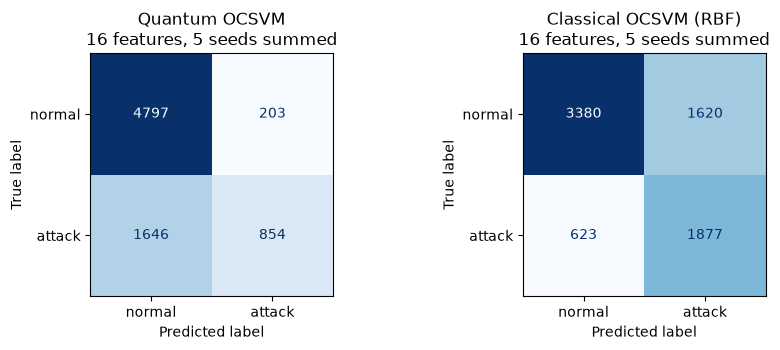

In [13]:
# Confusion matrices for the headline setting (16 features, 8 qubits), summed over the seeds. Attack = positive class.
nf = N_FEATURES_MAIN
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, key, title in zip(ax, ["q", "c"], ["Quantum OCSVM", "Classical OCSVM (RBF)"]):
    cm = sum(m["cm"] for m in RESULTS[nf][key])
    ConfusionMatrixDisplay(cm, display_labels=["normal", "attack"]).plot(ax=a, colorbar=False, cmap="Blues", values_format="d")
    a.set_title(f"{title}\n{nf} features, {N_SEEDS} seeds summed")
plt.tight_layout(); plt.show()

## 8. Re-drawing the paper's Fig. 5: the kernel matrices

Fig. 5 of the paper shows the fidelity kernel for the training set (training x training, mostly bright = high fidelity) and
for the test set (test x training) with 1000 normal samples first, followed by 500 anomalous ones; the anomalous block is
dark (low fidelity). Below we draw the same two pictures from our 16-feature / 8-qubit run (seed 0), and measure the effect
without any threshold: the mean fidelity of a test sample to the training set, and the ROC-AUC obtained when that mean is
used as anomaly score.

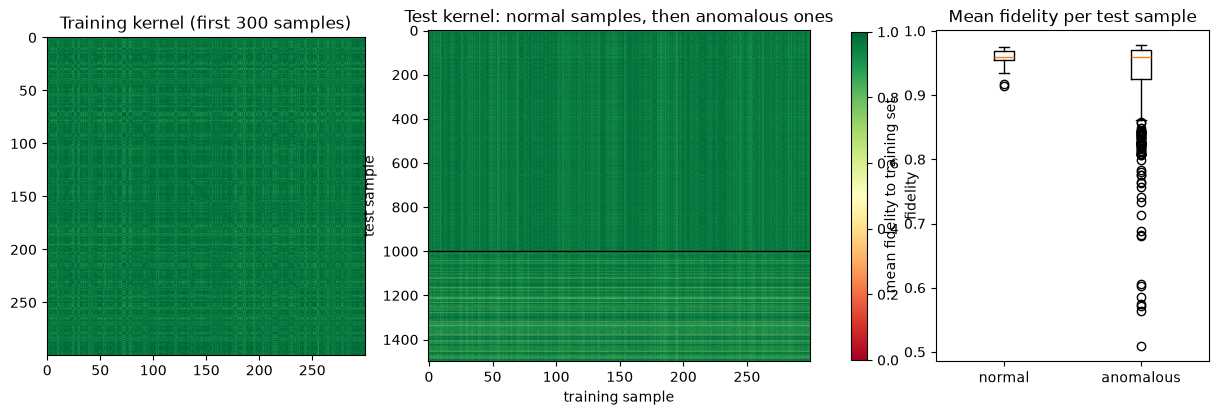

mean fidelity: normal 0.960 | anomalous 0.929 | AUC of '1 - mean fidelity' as anomaly score: 0.555
training kernel: mean off-diagonal fidelity 0.964


In [14]:
Ktr0, Kte0, yte0 = KEEP["Ktr"], KEEP["Kte"], KEEP["yte"]
ns = min(300, Ktr0.shape[0])
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3), gridspec_kw=dict(width_ratios=[1, 1.2, 0.8]))
im = ax[0].imshow(Ktr0[:ns, :ns], cmap="RdYlGn", vmin=0, vmax=1); ax[0].set_title(f"Training kernel (first {ns} samples)")
ax[1].imshow(Kte0[:, :ns], cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
ax[1].axhline((yte0 == 0).sum(), color="k", lw=1); ax[1].set_title("Test kernel: normal samples, then anomalous ones")
ax[1].set_ylabel("test sample"); ax[1].set_xlabel("training sample"); plt.colorbar(im, ax=ax[:2], fraction=0.02, label="fidelity")
mf = Kte0.mean(axis=1)
ax[2].boxplot([mf[yte0 == 0], mf[yte0 == 1]], tick_labels=["normal", "anomalous"]); ax[2].set_ylabel("mean fidelity to training set")
ax[2].set_title("Mean fidelity per test sample")
plt.show()
auc_fid = roc_auc_score(yte0, -mf)
print(f"mean fidelity: normal {mf[yte0==0].mean():.3f} | anomalous {mf[yte0==1].mean():.3f} | AUC of '1 - mean fidelity' as anomaly score: {auc_fid:.3f}")
print(f"training kernel: mean off-diagonal fidelity {(Ktr0.sum()-np.trace(Ktr0))/(Ktr0.size-len(Ktr0)):.3f}")

## 9. What matters? Ablations on the choices the paper leaves open

Three questions, each answered with the 16-feature setting and the hyper-parameters tuned above:

1. **Which labelled data feeds the decision tree?** `calibration block` (this notebook), `train2 only` (labelled data from
   the training files alone: just two short attack episodes), and `all labelled data` (the paper-literal reading, which
   includes the evaluation attacks and therefore leaks; shown only for comparison).
2. **How are angles scaled?** z-score x `bw` (this notebook) or min-max to [-pi, pi] per feature (the paper's wording).
3. **What happens at the real 4 % anomaly rate?** The paper's 2:1 test mix is artificial; the last table scores a random
   sample of evaluation windows at their natural class ratio.

In [15]:
nf = N_FEATURES_MAIN
rank_train2, _ = gini_rank(X_tr2, y_tr2)
rank_leaky, _ = gini_rank(np.vstack([X_cal, X_ev]), np.r_[y_cal, y_ev])      # paper-literal reading: sees test attacks
rows = []
for name, rank, norm in [("tree on calibration block, z x bw (this notebook)", RANK_CAL, "z"),
                         ("tree on train2 only, z x bw", rank_train2, "z"),
                         ("tree on ALL labelled data (leaky), z x bw", rank_leaky, "z"),
                         ("tree on calibration block, min-max to [-pi, pi]", RANK_CAL, "mm")]:
    res, _, _ = run_config(nf, rank[:nf], HP[nf], N_SEEDS, with_sup=False, norm=norm)
    for k, lab in (("q", "quantum"), ("c", "classical")):
        if norm == "mm" and k == "c": continue          # the classical model does not use this scaling
        rows.append(dict(setting=name, model=lab, **{m: f"{np.mean([x[m] for x in res[k]]):.3f}" for m in ("acc", "f1", "auc")}))
abl = pd.DataFrame(rows); display(abl)

,setting,model,acc,f1,auc
0,"tree on calibration block, z x bw (this notebook)",quantum,0.753,0.719,0.594
1,"tree on calibration block, z x bw (this notebook)",classical,0.701,0.708,0.811
2,"tree on train2 only, z x bw",quantum,0.804,0.790,0.669
3,"tree on train2 only, z x bw",classical,0.790,0.787,0.795
4,"tree on ALL labelled data (leaky), z x bw",quantum,0.837,0.829,0.809
5,"tree on ALL labelled data (leaky), z x bw",classical,0.850,0.849,0.851
6,"tree on calibration block, min-max to [-pi, pi]",quantum,0.342,0.185,0.699


In [16]:
# Natural prevalence: random evaluation windows at their true ~4 % anomaly rate (one draw, 16 and 8 features)
r = np.random.default_rng(SEED + 777); idx = r.choice(len(X_ev), N_REALISTIC, replace=False); yr = y_ev[idx]
tr = draw_train(0); rows = []
for nf in (8, N_FEATURES_MAIN):
    sel = RANK_CAL[:nf]; Ztr, Zr = Z(X_pool[tr]), Z(X_ev[idx])
    A, B = angles(Ztr, sel, HP[nf]["q"]["bw"]), angles(Zr, sel, HP[nf]["q"]["bw"])
    p, sc = ocsvm_scores_q(fast_kernel(A), fast_kernel(B, A), HP[nf]["q"]["nu"]); mq = metrics(yr, p, sc)
    Ac, Bc = angles(Ztr, sel, 1.0), angles(Zr, sel, 1.0)
    p, sc = ocsvm_scores_c(Ac, Bc, HP[nf]["c"]["nu"], HP[nf]["c"]["gmult"]); mc = metrics(yr, p, sc)
    for lab, m in (("quantum OCSVM", mq), ("classical OCSVM", mc)):
        rows.append(dict(features=nf, model=lab, accuracy=round(m["acc"], 3), weighted_F1=round(m["f1"], 3), attack_precision=round(m["att_prec"], 3),
                         attack_recall=round(m["att_rec"], 3), attack_F1=round(m["att_f1"], 3), AUC=round(m["auc"], 3)))
print(f"{N_REALISTIC} random evaluation windows, anomaly rate {100*yr.mean():.2f} %; predicting 'normal' for everything would give accuracy {1-yr.mean():.3f}")
display(pd.DataFrame(rows))

20000 random evaluation windows, anomaly rate 4.12 %; predicting 'normal' for everything would give accuracy 0.959


,features,model,accuracy,weighted_F1,attack_precision,attack_recall,attack_F1,AUC
0,8,quantum OCSVM,0.949,0.946,0.346,0.275,0.307,0.553
1,8,classical OCSVM,0.686,0.780,0.096,0.788,0.171,0.835
2,16,quantum OCSVM,0.934,0.939,0.276,0.376,0.319,0.592
3,16,classical OCSVM,0.613,0.725,0.078,0.775,0.142,0.823


## 10. The same kernel through Qiskit's `FidelityStatevectorKernel` (headline run)

To close the loop with the paper's software stack, the headline setting (16 features, 8 qubits, seed 0) is run once more with
`FidelityStatevectorKernel(feature_map=paper_feature_map(16))` for both the training kernel and the test kernel, and fed to the
same `OneClassSVM(kernel="precomputed")` after `exp(K)`. The kernel matrices must equal those of the fast simulator and the
metrics must be identical.

In [17]:
nf = N_FEATURES_MAIN; hp = HP[nf]
qk = FidelityStatevectorKernel(feature_map=paper_feature_map(nf), enforce_psd=False)
A, B, yte0 = KEEP["A"], KEEP["B"], KEEP["yte"]
t = time.time(); Ktr_qk = qk.evaluate(A); Kte_qk = qk.evaluate(B, A); t_qk = time.time() - t
print(f"Qiskit kernel: {A.shape[0]} train x train and {B.shape[0]} test x train entries in {t_qk:.0f} s "
      f"(fast simulator: {TIMES[nf]['q'][0]:.1f} s including the SVM)")
print("max |Qiskit - fast| over train kernel:", np.abs(Ktr_qk - KEEP["Ktr"]).max(), "| test kernel:", np.abs(Kte_qk - KEEP["Kte"]).max())
assert np.allclose(Ktr_qk, KEEP["Ktr"], atol=1e-10) and np.allclose(Kte_qk, KEEP["Kte"], atol=1e-10)
p, sc = ocsvm_scores_q(Ktr_qk, Kte_qk, hp["q"]["nu"]); m_qk = metrics(yte0, p, sc)
m_fast = RESULTS[nf]["q"][0]
print(f"Qiskit-kernel OCSVM : acc {m_qk['acc']:.3f}  weighted F1 {m_qk['f1']:.3f}  AUC {m_qk['auc']:.3f}")
print(f"fast-simulator OCSVM: acc {m_fast['acc']:.3f}  weighted F1 {m_fast['f1']:.3f}  AUC {m_fast['auc']:.3f}")
assert np.isclose(m_qk["acc"], m_fast["acc"]) and np.isclose(m_qk["f1"], m_fast["f1"])

Qiskit kernel: 1000 train x train and 1500 test x train entries in 93 s (fast simulator: 3.8 s including the SVM)
max |Qiskit - fast| over train kernel: 9.547918011776346e-15 | test kernel: 4.773959005888173e-15


Qiskit-kernel OCSVM : acc 0.751  weighted F1 0.715  AUC 0.564
fast-simulator OCSVM: acc 0.751  weighted F1 0.715  AUC 0.564


## 11. Side by side with the paper

The verdict rule used for every numeric claim: **reproduced** if our mean is within 2 accuracy points (0.02 for F1, precision
and recall) of the paper's value; otherwise **not reached** (ours is lower) or **exceeded** (ours is higher), with the gap.
Claims about relations (quantum better than classical, 16 features best, anomalies have lower fidelity) are judged on the
same means. The statistical spread over seeds is given in Section 7.

In [18]:
PAPER = {  # Table I of the paper: (accuracy %, precision, recall, F1)
    ("quantum", 8): (86, .87, .86, .85), ("quantum", 16): (87, .88, .87, .86), ("quantum", 24): (82, .82, .82, .82),
    ("classical", 8): (74, .81, .74, .67), ("classical", 16): (73, .81, .73, .65), ("classical", 24): (72, .79, .72, .65)}
def verdict(ours, paper, tol):
    gap = ours - paper
    return "reproduced" if abs(gap) <= tol else (f"exceeded (+{abs(gap):.3f})" if gap > 0 else f"not reached ({gap:.3f})")
rows = []
mean = lambda nf, key, m: np.mean([x[m] for x in RESULTS[nf][key]])
for (kind, nf), (pacc, ppr, prc, pf1) in PAPER.items():
    key = "q" if kind == "quantum" else "c"
    if nf not in RESULTS: continue
    for metric, pv, mk, tol in (("accuracy", pacc / 100, "acc", .02), ("precision", ppr, "prec", .02), ("recall", prc, "rec", .02), ("F1", pf1, "f1", .02)):
        o = mean(nf, key, mk)
        rows.append(dict(claim=f"{kind} {nf} features: {metric}", paper=pv, notebook=round(o, 3), verdict=verdict(o, pv, tol)))
q16, c16 = mean(N_FEATURES_MAIN, "q", "acc"), mean(N_FEATURES_MAIN, "c", "acc")
qf16, cf16 = mean(N_FEATURES_MAIN, "q", "f1"), mean(N_FEATURES_MAIN, "c", "f1")
rows.append(dict(claim="quantum minus classical accuracy, 16 features (points)", paper=14, notebook=round(100 * (q16 - c16), 1),
                 verdict=verdict(100 * (q16 - c16), 14, 2)))
rows.append(dict(claim="quantum minus classical weighted F1, 16 features", paper=0.21, notebook=round(qf16 - cf16, 3), verdict=verdict(qf16 - cf16, .21, .02)))
accs = {nf: mean(nf, "q", "acc") for nf in FEATURE_COUNTS}
rows.append(dict(claim="16 features (8 qubits) is the best quantum setting", paper="yes", notebook=f"best = {max(accs, key=accs.get)} features",
                 verdict="reproduced" if max(accs, key=accs.get) == 16 else "not reached"))
mf = KEEP["Kte"].mean(axis=1); yk = KEEP["yte"]
rows.append(dict(claim="anomalous test samples have lower fidelity to the training set (Fig. 5)", paper="yes",
                 notebook=f"{mf[yk==1].mean():.3f} vs {mf[yk==0].mean():.3f} (AUC {roc_auc_score(yk, -mf):.2f})",
                 verdict="reproduced" if mf[yk == 1].mean() < mf[yk == 0].mean() else "not reached"))
cq, cc = RESULTS[N_FEATURES_MAIN]["q"], RESULTS[N_FEATURES_MAIN]["c"]
ap, ar = np.mean([m["att_prec"] for m in cc]), np.mean([m["att_rec"] for m in cc])
rows.append(dict(claim="classical kernel misses anomalies (attack-class recall < attack-class precision), 16 features", paper="recall low, precision high",
                 notebook=f"attack precision {ap:.2f} / attack recall {ar:.2f}",
                 verdict="reproduced" if ar < ap else "not reached (opposite pattern: many false alarms, few misses)"))
rows.append(dict(claim="Table II (other authors, other datasets)", paper="quoted", notebook="-", verdict="cannot be checked (not this paper's experiment)"))
cmp_df = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90); display(cmp_df)
print("\nTally:", cmp_df["verdict"].str.split(" ").str[0].value_counts().to_dict())

,claim,paper,notebook,verdict
0,quantum 8 features: accuracy,0.86,0.739,not reached (-0.121)
1,quantum 8 features: precision,0.87,0.769,not reached (-0.101)
2,quantum 8 features: recall,0.86,0.739,not reached (-0.121)
3,quantum 8 features: F1,0.85,0.688,not reached (-0.162)
4,quantum 16 features: accuracy,0.87,0.753,not reached (-0.117)
5,quantum 16 features: precision,0.88,0.769,not reached (-0.111)
6,quantum 16 features: recall,0.87,0.753,not reached (-0.117)
7,quantum 16 features: F1,0.86,0.719,not reached (-0.141)
8,quantum 24 features: accuracy,0.82,0.762,not reached (-0.058)
9,quantum 24 features: precision,0.82,0.79,not reached (-0.030)



Tally: {'not': 19, 'exceeded': 8, 'reproduced': 2, 'cannot': 1}


﻿## 12. Reading the paper critically

Numbers below are from the full run (`FAST_MODE = False`, 5 seeds, 1000 training windows, 1000 normal + 500 anomalous test windows); a re-run on another machine should match to the third decimal because every seed is fixed.

**What was reproduced.** The pipeline runs end to end on the public HAI 20.07 data with the paper's design: 60-s moving average, Gini-ranked sensors, a 3-fold-repeated `U` / CNOT-chain / rotation feature map with two features per qubit, a fidelity kernel (identical in the fast simulator, in hand-made `Statevector` overlaps and in Qiskit's `FidelityStatevectorKernel` to 1e-14), `exp(K)` post-processing and a precomputed One-Class SVM trained on normal data only. The anomaly rate of the test files is 3.9 to 4.1 %, as the paper says. The paper's *classical* numbers are in the right range (our classical OCSVM: 70 to 81 % accuracy against 72 to 74 % in Table I, with a large seed-to-seed spread of up to 5 points).

**What was not reproduced.** The quantum numbers. With 16 features / 8 qubits the quantum OCSVM reaches 75.3 +- 1.5 % accuracy and weighted F1 0.72 +- 0.02, against 87 % and 0.86 in the paper (about 12 points and 0.14 F1 short). The same gap appears for 8 features (73.9 % against 86 %) and 24 features (76.2 % against 82 %). The advantage over the classical counterpart shrinks from the paper's 14 points / 0.21 F1 to 5 points / 0.01 F1 at 16 features, and at 8 and 24 features the classical OCSVM is actually better than the quantum one. The paper's "16 features is best" ordering is not seen (24 features is nominally best here, but the three quantum accuracies lie within about 2 points of one another).

**Why the numbers may differ, from the ablations in Section 9.**
1. *The feature ranking is the most sensitive unspecified step.* A decision tree needs labels. When the tree is fitted on labelled data that includes the evaluation attacks (the literal reading of the paper, which would leak test information), the quantum OCSVM reaches 83.7 % accuracy (F1 0.83), within 3.3 points of the paper's 87 %, but the classical OCSVM rises to 85.0 % too. With a leak-free ranking (calibration block, or `train2` only) the quantum model gives 75 to 80 %. So the paper's number is plausible under a ranking that sees the test attacks, and the quantum-versus-classical gap is not an effect of the kernel in our hands.
2. *Angle scaling.* Min-max scaling of every feature to [-pi, pi], as the paper writes, makes the fidelity between two different windows almost zero for 16 features (the kernel matrix is close to the identity), the OCSVM then calls every test window anomalous (accuracy 34 %, the share of anomalies in the 2:1 test mix is 33 %). A bandwidth well below 1 was needed; the best bandwidths found on the validation block are at the small end of our grid (0.025 to 0.05), where the kernel is almost flat (mean fidelity about 0.96). That is a smooth, nearly linear-in-angle similarity, not a highly expressive quantum feature space. The paper does not mention such a scale factor, but its Fig. 5 shows training fidelities close to 1, which suggests the authors' data also occupied a small part of the angle range.
3. *The OCSVM threshold.* Both OCSVMs decide with a threshold set by `nu` on the training data. Test windows from other days sit further from the training cloud than held-out training windows, so the tuned `nu` is tiny (0.001 to 0.003). Accuracy therefore reflects how well that threshold transfers, and not only how well the kernel separates the classes. The threshold-free AUC tells a different story: the classical RBF OCSVM ranks anomalies better (AUC 0.81 at 16 features) than the quantum one (0.59). The mean fidelity of anomalous test windows to the training set is lower than that of normal windows (0.929 against 0.960), so the *direction* of the paper's Fig. 5 is reproduced, but the effect is small (AUC 0.55 for "1 minus mean fidelity"), far from the clear dark block drawn in the paper.
4. *Class mix.* The 1000 + 500 test is a 2:1 mix, while HAI is about 4 % anomalous. At the natural rate (Section 9), the 16-feature quantum OCSVM has 93.4 % accuracy, but only 28 % attack precision and 38 % attack recall; a model that says "normal" for everything scores 95.9 %. The classical OCSVM flags 78 % of the attacks but with 8 % precision. Accuracy and weighted F1 on a balanced-ish mix are generous measures for a deployed detector.
5. *Supervised references.* With only 1500 labelled windows, a plain RBF `SVC` on the same 16 features reaches 91.6 % accuracy (AUC 0.95) and a random forest 84.3 %. A labelled-quantum-kernel `SVC` reaches 76.5 %. If labelled anomalies exist, the one-class framing is not needed, and the quantum kernel is not the better kernel on these inputs.

**Other caveats.** (i) Windows are labelled at their last second and a window that overlaps an attack but ends after it is dropped from the normal class; a different convention shifts the numbers. (ii) The paper does not state training-set size, `nu`, how the moving-average windows were labelled, which part of the data trained the Gini tree, or the exact gates of Fig. 4. (iii) The evaluation windows overlap in time (59 of 60 samples shared with a neighbour), so the effective number of independent test samples is smaller than 1500; the seed-to-seed spread understates the true uncertainty. (iv) Table I gives no standard deviations; the 14-point gap reported "beyond statistical variation" cannot be checked, and our classical OCSVM alone varies by up to 5 points between seeds. (v) The paper itself ran a noiseless simulation, so nothing is said about hardware, and the O(N_train x N_test x shots) circuit count it mentions makes second-resolution monitoring impractical on a real device.

**Verdict.** The pipeline and its qualitative message (a one-class SVM on a quantum fidelity kernel can flag HAI attacks above chance, with anomalies less similar to the normal data) are reproduced. The headline numbers (87 % / 0.86) and the claimed 14-point advantage over the classical kernel are not reached with a leak-free feature ranking and are matched only partly when the ranking sees the test attacks, in which case the classical model matches them as well.

## 13. Exercises

1. **Bandwidth.** Re-run Section 6 with `BW_GRID = (0.02, 0.05, 1.0, 3.0)`. Plot the mean off-diagonal training fidelity against
   `bw`. Why does a large `bw` make every test sample "anomalous" and a tiny `bw` make none of them anomalous?
2. **Feature order.** Replace the Gini ranking by a random sensor order, by the sensors with the largest training variance, and by
   an ANOVA F-test on the calibration block. Which ranking helps the quantum and which the classical OCSVM?
3. **Circuit design.** Change `REPS` to 1, 2, 5, remove the entangling CNOT chain, or replace the `U` gate by `RY` only. Is the 3x
   repetition of the paper needed? Use the AUC, not the thresholded accuracy.
4. **Window length.** Change `WINDOW` from 60 to 10 and 300. HAI attacks last 5 to 10 minutes: how does the window length trade off
   noise suppression against detection delay?
5. **Noise.** Replace the exact statevector by a shot-based fidelity estimate (`SHOTS = 1024`, the compute-uncompute circuit with a
   `FakeBackend` from `qiskit_ibm_runtime.fake_provider`) for 4 qubits and 100 training samples. How much does the AUC of
   Section 8 drop, and does `exp(K)` help or hurt?